# **Convolutional Neural Networks**

## Table of Contents
- [Theory](#theory)
    - [What is convolution?](#conv)
    - [CNNs](#cnns)
    - [Specific Layers](#conv_layers)
- [Image Classification](#im_cnn)
    - [Transfer Learning](#tl)
- [Malware Image Classification](#malware)
- [Homework](#hw)
    - [Homework A: Transfer Learning for Malware Family Classification](#hw_a)
    - [Homework B: Explaining a Malware Image Classifier](#hw_b)

## **Theory** <a class="anchor" id="theory"></a>

### **What is convolution?** <a class="anchor" id="conv"></a>

In the context of signal processing, **convolution** involves applying a filter (kernel) to an input signal to produce an output with some desired properties.

Convolution can be defined in an arbitrary number of dimensions, for example:
- 1D - time series modeling, audio signal processing
- 2D - image blurring, edge detection
- 3D - video processing, volumetric medical data
- 4D - [Minkowski Convolutional Neural Networks](https://openaccess.thecvf.com/content_CVPR_2019/papers/Choy_4D_Spatio-Temporal_ConvNets_Minkowski_Convolutional_Neural_Networks_CVPR_2019_paper.pdf) for spatio-temporal perception
- 5D, 6D, 7D, ... - 🤔??

### **1D Convolution ⬅️➡️**

Given:
- a 1D input signal $x = [x_1, x_2, \dots, x_n] \in \mathbb{R}^n$
- a 1D kernel $w = [w_1, w_2, \dots, w_k] \in \mathbb{R}^k$, 

the output $y = [y_1, y_2, \dots, y_{n-k+1}] \in \mathbb{R}^{n-k+1}$ is defined as follows:
$$y = x \ast w$$
$$y_i = \sum_{m=0}^{k-1} w_m x_{i+m},\, \forall i \in \{1, \dots, n-k+1\}$$

which are given by the sum of succesive dot products between input $x$ and shifted versions of kernel $w$ (in this case, with a *stride* of 1).

<div style="text-align: center;">
  <img src="imgs/1d_conv.gif" alt="description" width="600"/>
  <figcaption>1D Conv Animation</figcaption>
</div>

### **2D convolution ⬅️➡️,⬆️⬇️**

Given:
- 2D input signal $X = \{x_{i, j}\}_{1\leq i \leq N, \,1\leq j \leq M} \in \mathbb{R}^{N\times M}$
- a 2D kernel $W = \{w_{i, j}\}_{1\leq i \leq K, \,1\leq j \leq K} \in \mathbb{R}^{K\times K}$, 

the output $Y = \{y_{i, j}\}_{1\leq i \leq N-K+1, \,1\leq j \leq M-K+1} \in \mathbb{R}^{N-K+1\times M-K+1}$ is defined as follows:
$$Y = X \ast W$$
$$y_{i, j} = \sum_{n=0}^{K-1} \sum_{m=0}^{K-1} w_{n, m} x_{i+n, j+m},\, \forall (i, j) \in \{1, \dots, N-K+1\} \times \{1, \dots, M-K+1\}$$

which are given by *sliding* the kernel $W$ along $K\times K$ neighbourhoods from the input signal $X$, centered in $(i, j)$, and taking succesive dot products between $X$ and $W$. 

<div style="text-align: center;">
  <img src="imgs/conv_gif.gif" alt="description" width="600"/>
  <figcaption>2D Conv Animation</figcaption>
</div>

### **Convolutional Neural Networks (CNNs)** <a class="anchor" id="cnns"></a>

<div style="text-align: center;">
  <img src="imgs/cnn.PNG" alt="description" width="1000"/>
  <figcaption>Diagram of a simplified CNN used for classification. <a href="https://miro.medium.com/v2/resize:fit:2000/format:webp/1*Vior6yy6_qN5rBv5Os0kGA.png">Source</a></figcaption>
</div>

### **1D Convolution** (for CNNs)

Given a feature tensor $X$ of shape $(B, C_{in}, L_{in})$, a kernel $W$ of shape $(C_{out}, C_{in}, K)$, and an output $Y$ of shape $(B, C_{out}, L_{out})$, where $C_{in}/C_{out}$ represent the number of input/output channels, $B$ the batch size, and $L_{in}/L_{out}$ the length of input/output sequences, the 1D convolution is given by:

$$Y_{b, c_{\text{out}}, l} = \sum_{c_{\text{in}}=1}^{C_{\text{in}}} \sum_{m=0}^{K-1} X_{b, c_{\text{in}}, l S + m}  W_{c_{\text{out}}, c_{\text{in}}, m},\, \forall b\in\{1, \dots, B\}, c_{\text{out}}\in \{1, \dots, C_{out}\}, l\in \{1, \dots, L_{out}\}
$$

where $S$ denotes the *stride* by which the kernel is shifted along the convolution dimension. For a $S \geq 1$, the length of the output sequence is given by the following:
$$L_{\text{out}} = \left\lfloor \frac{{L_{\text{in}} - K}}{S} \right\rfloor + 1
$$

Therefore, a stride $S > 1$ can be seen as a [downsampling](https://en.wikipedia.org/wiki/Downsampling_(signal_processing)) operation, filtering the most general features, while reducing the influence of underlying noise. 

This convolution can be seen as a multi-input multi-output (**MIMO**) operation, where $X$ is composed of multiple ($C_{in}$) input sequences of length $L_{in}$ and $Y$ is built by independently convolving X with  $C_{out}$ filters, each filter having the dimensionality $(C_{in}, K)$.

### **2D Convolution** (for CNNs)

Analogously, given:
- a feature tensor $X$ of shape $(B, C_{in}, H_{in}, W_{in})$
- a kernel $W$ of shape $(C_{out}, C_{in}, K, K)$ (it could also be non-square), 

the output $Y$ of shape $(B, C_{out}, H_{out}, W_{out})$ of the 2D convolution between $X$ amd $W$ is:

$$Y_{b, c_{\text{out}}, h, w} = \sum_{c_{\text{in}}=1}^{C_{\text{in}}} \sum_{m=0}^{K-1} \sum_{n=0}^{K-1} X_{b, c_{\text{in}}, h S + m, w S + n}  W_{c_{\text{out}}, c_{\text{in}}, m, n},\, \forall b\in\{1, \dots, B\}, c_{\text{out}}\in \{1, \dots, C_{out}\}, (h, w)\in \{1, \dots, H_{out}\} \times \{1, \dots, W_{out}\}
$$

<div style="text-align: center;">
  <img src="imgs/cnn_2.png" alt="description" width="500"/>
  <figcaption>2D Conv diagram, using 3D tensors</figcaption>
</div>

This can also be seen as $C_{out}$ succesive independent convolutions between input $X$ and filters of shape $(C_{in}, K, K)$, each of which results in a single-channel output of shape $(H_{out}, W_{out})$. Note that the kernel $W$ is constructed and applied s.t. all input channels contribute to the output.

**Note: The dimensionality of the convolution operation refers to the number of directions the kernel *moves* along the input tensor, not the dimensionality of the kernel!**

There are many other varieties of convolution: [Pointwise](https://paperswithcode.com/method/pointwise-convolution), [Dilated](https://www.geeksforgeeks.org/dilated-convolution/), [Depthwise Separable](https://paperswithcode.com/method/depthwise-separable-convolution), [Spatially Separable](https://paperswithcode.com/method/spatially-separable-convolution), [Grouped](https://blog.yani.ai/filter-group-tutorial/), . . .

### ***Why does convolution work?***

>- **Local connectivity**: preserves the spatial relationship by taking into account only small regions when computing the output elements
>
>- **Location-invariant**: Convolution can detect patterns regardless their position in the input signal, exhibiting *Translation Invariance* 
>
>- **Parameter sharing**: The same set of weights is used across all spatial locations in the input signal, helping in parameter reduction and robustness to overifitting (compared to fully-connected counterparts)

<div style="text-align: center;">
  <img src="imgs/plane.png" alt="description" width="1200"/>
  <figcaption>2D Conv Example</figcaption>
</div>

### **Specific Layers** <a class="anchor" id="conv_layers"></a>

Let's generate some 1D and 2D data to work on:

In [1]:
from torch.nn import Conv1d, Conv2d, MaxPool1d, MaxPool2d, AvgPool1d, AvgPool2d, AdaptiveMaxPool2d
from torchvision.io import read_image
import matplotlib.pyplot as plt
import numpy as np
import torch

import sys

import utils
import importlib
_ = importlib.reload(utils)

In [2]:
### Generate a 1D signal with multiple channels
frequencies = [0.5, 0, 1.5, 5.0] 
amplitudes = [1.0, 0.5, 0.3, 1.0]    
phases = [0, 0.5, 1.0, 1.5]       

data_1d = utils.generate_toy_signal(1, frequencies, amplitudes, phases)
data_1d.shape

torch.Size([1, 4, 256])

In [3]:
data_2d = read_image("imgs/michael_scott.jpg")[None, ...] / 255.0 # add batch dimension & normalize
data_2d.shape

torch.Size([1, 3, 400, 400])

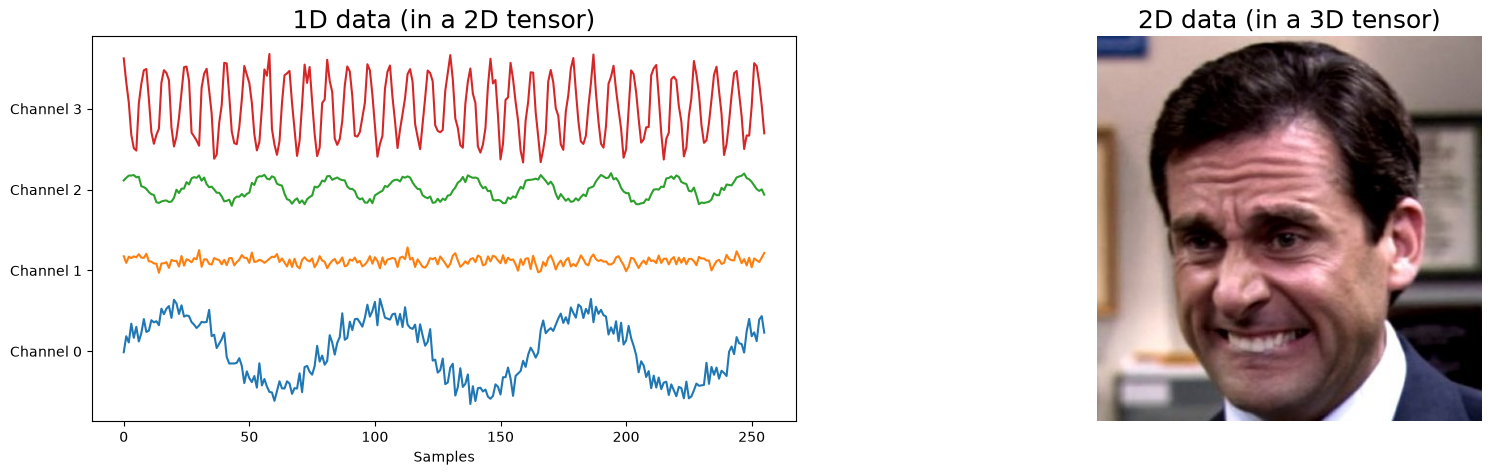

In [4]:
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
utils.plot_channels(data_1d)
plt.title("1D data (in a 2D tensor)", fontdict={"fontsize": 18})
plt.subplot(1, 2, 2)
plt.imshow(data_2d[0].permute(1, 2, 0))
plt.axis("off")
plt.title("2D data (in a 3D tensor)", fontdict={"fontsize": 18})
plt.show()

### I. Conv 1D / Conv 2D

Conv1d with kernel of shape: (3, 4, 5)


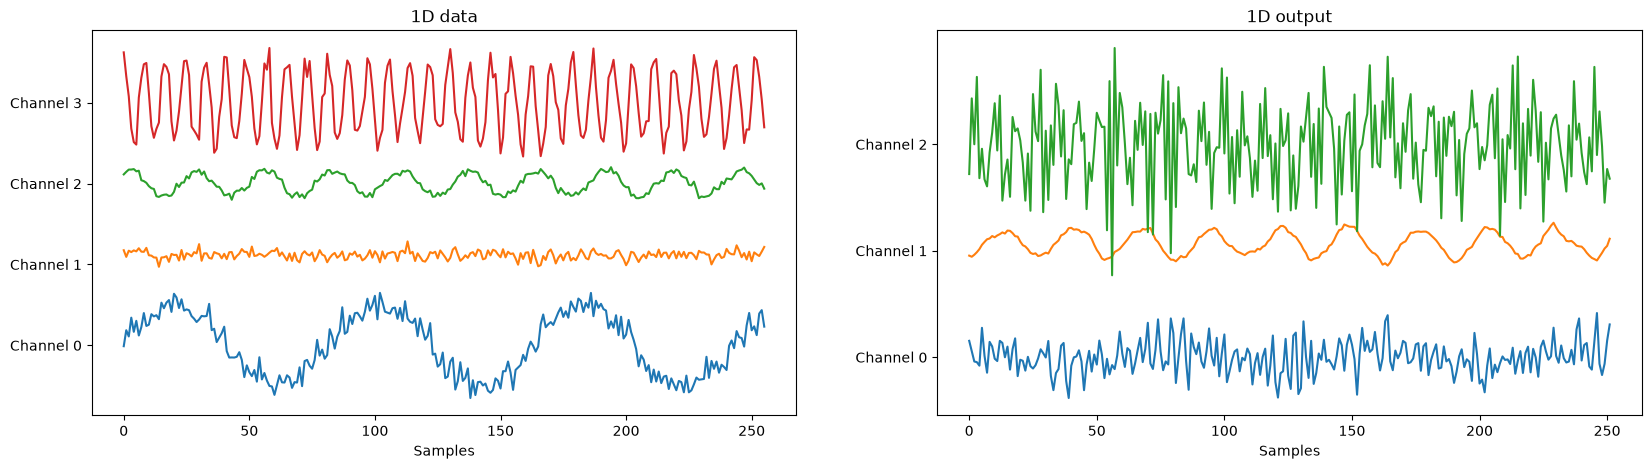

In [5]:
out_channels = 3
kernel_size = 5
conv1d = Conv1d(in_channels=data_1d.shape[1], out_channels=out_channels, kernel_size=kernel_size)

# Add some values to the kernel - (out_channels, in_channels, kernel_size)
weight_data = np.zeros((out_channels, data_1d.shape[1], kernel_size))
print(f"Conv1d with kernel of shape: {weight_data.shape}")

weight_data[0, 0] = np.array([0, -1, 0, 1, 0]) # this output only dependes on the input channel #0

# weight_data[i] -> (in_channels, K) (while i^th filter); weight_data[i, j] -> (K) (the i^th filter acting on j^th input channel)

weight_data[1, 1] = np.ones(kernel_size) / kernel_size
weight_data[1, 2] = -1 * np.ones(kernel_size) / kernel_size # the second output is the difference between averaged input channel #1 and averaged input channel #2

weight_data[2, -1] = np.array([-1, 1, -2, 1, -1]) # this output only dependes on the last input channel
# Add it to the layer
conv1d.weight.data = torch.tensor(weight_data, dtype=torch.float)

out_1d = conv1d(data_1d)

# Observe the output
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
utils.plot_channels(data_1d)
plt.title("1D data")
plt.subplot(1, 2, 2)
utils.plot_channels(out_1d.detach())
plt.title("1D output")
plt.show()

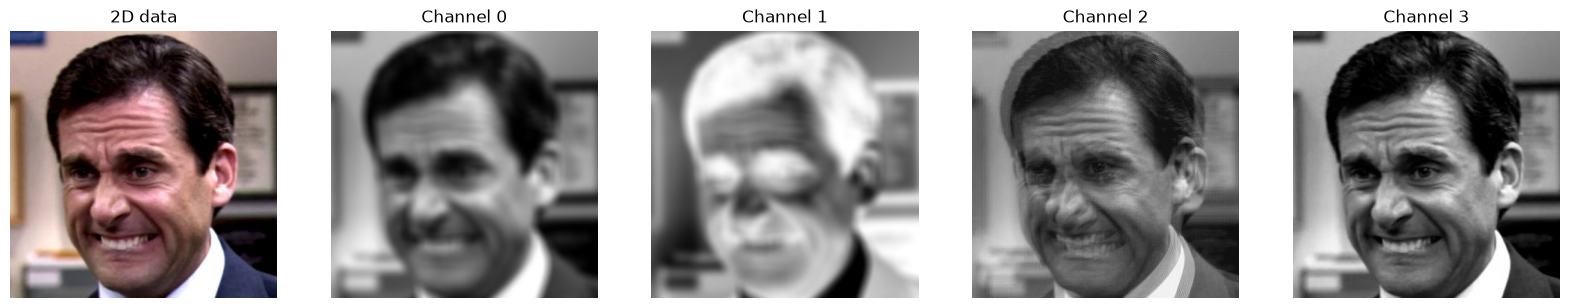

In [6]:
out_channels = 4
kernel_size = 15

conv2d = Conv2d(in_channels=data_2d.shape[1], out_channels=out_channels, kernel_size=kernel_size)

# Add some values to the kernel - (out_channels, in_channels, kernel_size)
weight_data = np.zeros((out_channels, data_2d.shape[1], kernel_size, kernel_size))

weight_data[0] = np.ones((data_2d.shape[1], kernel_size, kernel_size)) / (kernel_size**2)  # average all input channels - a.k.a blurring
weight_data[1] = -np.ones((data_2d.shape[1], kernel_size, kernel_size)) / (kernel_size**2)
vector = [(-1)**i for i in range(kernel_size)]
weight_data[2, 2] = np.diag(np.array(vector))  # performs some operation only on the last (blue) channel
weight_data[3, :, kernel_size // 2, kernel_size // 2] = np.array([0.216, 0.7152, 0.0722])  # RGB to gray weights
# Add it to the layer
conv2d.weight.data = torch.tensor(weight_data, dtype=data_2d.dtype)

out_2d = conv2d(data_2d)

# Observe the output
plt.figure(figsize=(20, 5))
plt.subplot(1, out_channels + 1, 1)
plt.title("2D data")
plt.imshow(data_2d[0].permute(1, 2, 0))
plt.axis("off")
for i in range(out_channels):
    plt.subplot(1, out_channels + 1, i + 2)
    plt.title(f"Channel {i}")
    plt.imshow(out_2d[0, i].detach().numpy(), cmap="gray")
    plt.axis("off")

### II. 1D/2D Max-pooling

In [ ]:
max1d = MaxPool1d(kernel_size=8, stride=4)

out_1d = max1d(data_1d)

# Observe the output
plt.figure(figsize=(20, 5))
plt.subplot(1, 2, 1)
utils.plot_channels(data_1d)
plt.title("1D data")
plt.subplot(1, 2, 2)
utils.plot_channels(out_1d.detach())
plt.title("1D output")
plt.show()

(np.float64(-0.5), np.float64(24.5), np.float64(24.5), np.float64(-0.5))

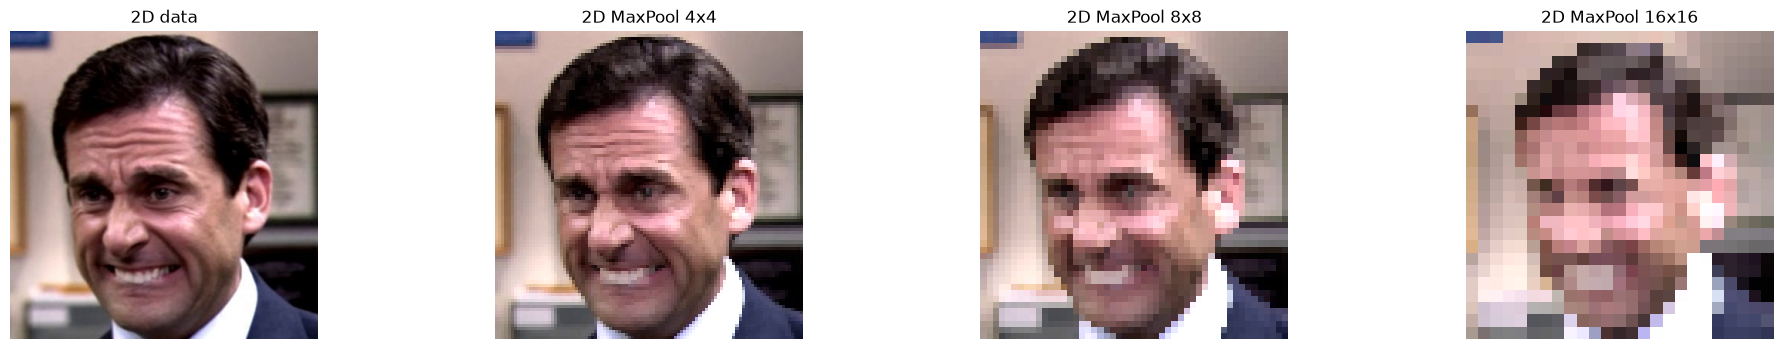

In [7]:
max2d_4 = MaxPool2d(kernel_size=4, stride=4)
max2d_8 = MaxPool2d(kernel_size=8, stride=8)
max2d_16 = MaxPool2d(kernel_size=16, stride=16)

out_2d_4 = max2d_4(data_2d)
out_2d_8 = max2d_8(data_2d)
out_2d_16 = max2d_16(data_2d)

# Observe the output
plt.figure(figsize=(24, 4))
plt.subplot(1, 4, 1)
plt.title("2D data")
plt.imshow(data_2d[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 2)
plt.title("2D MaxPool 4x4")
plt.imshow(out_2d_4[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 3)
plt.title("2D MaxPool 8x8")
plt.imshow(out_2d_8[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 4)
plt.title("2D MaxPool 16x16")
_ = plt.imshow(out_2d_16[0].permute(1, 2, 0))
plt.axis("off")

### III. 2D Average-pooling

(np.float64(-0.5), np.float64(368.5), np.float64(368.5), np.float64(-0.5))

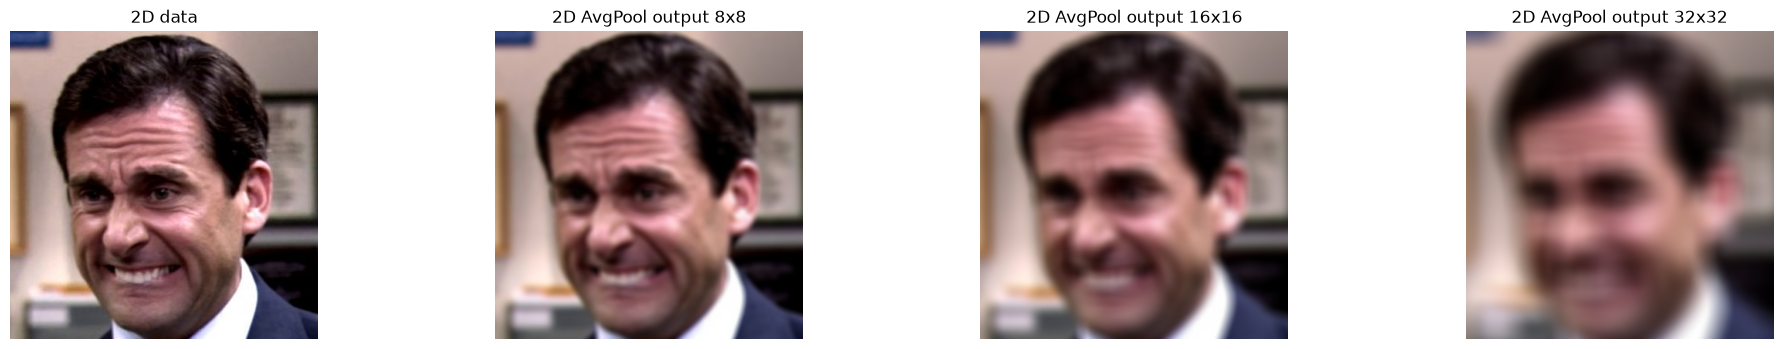

In [8]:
max2d_4 = AvgPool2d(kernel_size=8, stride=1)
max2d_8 = AvgPool2d(kernel_size=16, stride=1)
max2d_16 = AvgPool2d(kernel_size=32, stride=1)

out_2d_4 = max2d_4(data_2d)
out_2d_8 = max2d_8(data_2d)
out_2d_16 = max2d_16(data_2d)

# Observe the output
plt.figure(figsize=(24, 4))
plt.subplot(1, 4, 1)
plt.title("2D data")
plt.imshow(data_2d[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 2)
plt.title("2D AvgPool output 8x8")
plt.imshow(out_2d_4[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 3)
plt.title("2D AvgPool output 16x16")
plt.imshow(out_2d_8[0].permute(1, 2, 0))
plt.axis("off")
plt.subplot(1, 4, 4)
plt.title("2D AvgPool output 32x32")
_ = plt.imshow(out_2d_16[0].permute(1, 2, 0))
plt.axis("off")

### IV. Padding Layers (Optional)

Conv1d/2d layers can already implement some padding before performing convolution.

### V. Adapttive pooling

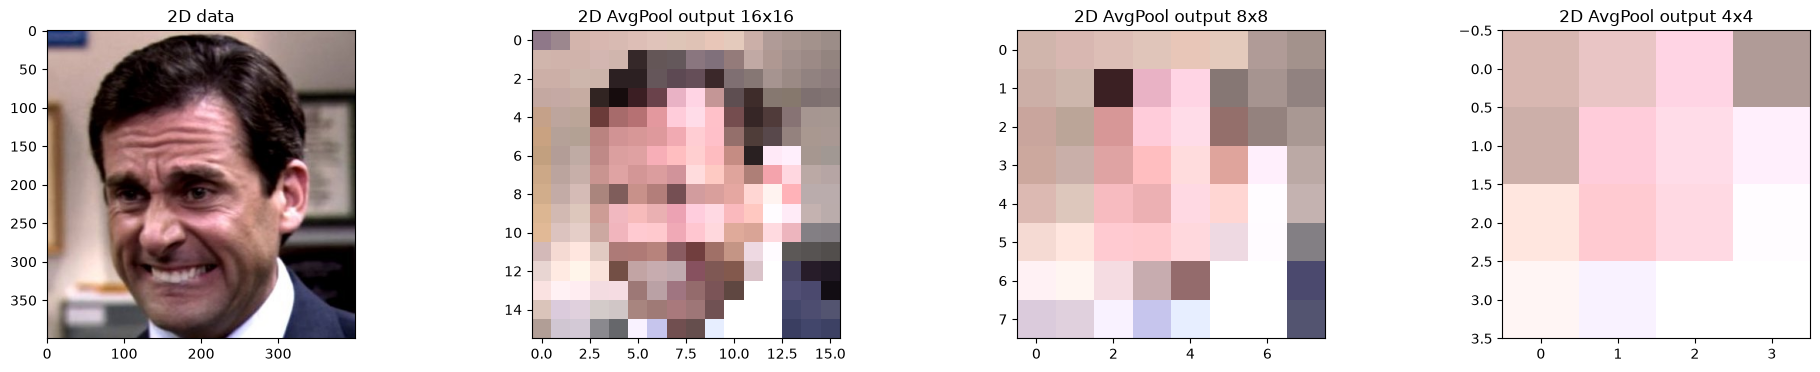

In [9]:
adapt2d_16 = AdaptiveMaxPool2d(16)
adapt2d_8 = AdaptiveMaxPool2d(8)
adapt2d_4 = AdaptiveMaxPool2d(4)

out_2d_16 = adapt2d_16(data_2d)
out_2d_8 = adapt2d_8(data_2d)
out_2d_4 = adapt2d_4(data_2d)

# Observe the output
plt.figure(figsize=(24, 4))
plt.subplot(1, 4, 1)
plt.title("2D data")
plt.imshow(data_2d[0].permute(1, 2, 0))
plt.subplot(1, 4, 2)
plt.title("2D AvgPool output 16x16")
plt.imshow(out_2d_16[0].permute(1, 2, 0))
plt.subplot(1, 4, 3)
plt.title("2D AvgPool output 8x8")
plt.imshow(out_2d_8[0].permute(1, 2, 0))
plt.subplot(1, 4, 4)
plt.title("2D AvgPool output 4x4")
_ = plt.imshow(out_2d_4[0].permute(1, 2, 0))

`AdaptivePooling` operators need only to specify the desired output dimension(s), thus not depending on the input resolution! This is important when training CNNs that should be able to operate on various image resolutions.

---

## **Image Classification** <a class="anchor" id="im_cnn"></a>

### **GTSRB dataset** ⛔

The GTSRB (German Traffic Sign Recognition Benchmark) consists of images of traffic signs commonly encountered on roads in Germany. he dataset comprises 43 different classes, images in the dataset vary in terms of lighting conditions, weather, and viewpoints, and may contain variations in aspect ratio.

In [11]:
import torchvision
import torchvision.transforms as transforms

h, w = 32, 32

data_transform = transforms.Compose([
    transforms.Resize((h, w)),
    transforms.ToTensor(),
])

gtsrb_train = torchvision.datasets.GTSRB(root="./data", split="train", download=True, transform=data_transform)
gtsrb_test = torchvision.datasets.GTSRB(root="./data", split="test", download=True, transform=data_transform)

Images are already normalized $[0, 1]$. Original images have a wide range of resolutions, from $15 \times 15$ to $250 \times 250$ pixels. 

In [12]:
print("Train images: ", len(gtsrb_train), "Test images: ", len(gtsrb_test))

x, y = gtsrb_train[0]
print("Input imaeg range: ", x.min(), x.max())
print("Input image size: ", x.shape)
print("Label: ", y)

Train images:  26640 Test images:  12630
Input imaeg range:  tensor(0.2118) tensor(1.)
Input image size:  torch.Size([3, 32, 32])
Label:  0


In [13]:
label_map = {
    0: 'Speed limit (20 km/h)',
    1: 'Speed limit (30 km/h)',
    2: 'Speed limit (50 km/h)',
    3: 'Speed limit (60 km/h)',
    4: 'Speed limit (70 km/h)',
    5: 'Speed limit (80 km/h)',
    6: 'End of speed limit (80 km/h)',
    7: 'Speed limit (100 km/h)',
    8: 'Speed limit (120 km/h)',
    9: 'No passing',
    10: 'No passing for vehicles over 3.5 t',
    11: 'Right-of-way at next intersection',
    12: 'Priority road',
    13: 'Yield',
    14: 'Stop',
    15: 'No vehicles',
    16: 'Vehicles over 3.5 t prohibited',
    17: 'No entry',
    18: 'General caution',
    19: 'Dangerous curve to the left',
    20: 'Dangerous curve to the right',
    21: 'Double curve',
    22: 'Bumpy road',
    23: 'Slippery road',
    24: 'Road narrows on the right',
    25: 'Road work',
    26: 'Traffic signals',
    27: 'Pedestrians',
    28: 'Children crossing',
    29: 'Bicycles crossing',
    30: 'Beware of ice/snow',
    31: 'Wild animals crossing',
    32: 'End of all speed and passing limits',
    33: 'Turn right ahead',
    34: 'Turn left ahead',
    35: 'Ahead only',
    36: 'Go straight or right',
    37: 'Go straight or left',
    38: 'Keep right',
    39: 'Keep left',
    40: 'Roundabout mandatory',
    41: 'End of no passing',
    42: 'End of no passing by vehicles over 3.5 t'
}

Check the color distribution in some partition of your data:

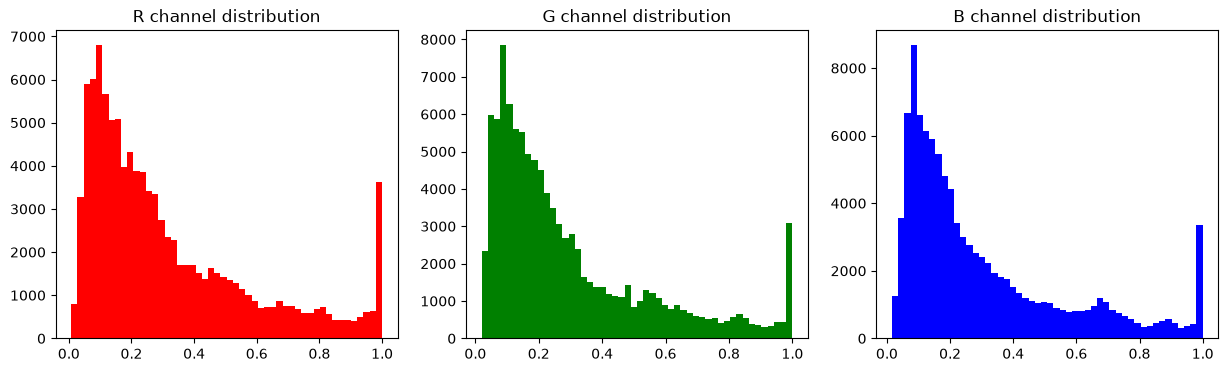

In [14]:
import numpy as np
import matplotlib.pyplot as plt

# Collect some data
data_rgb = [[], [], []]
num_samples = 100
for i in range(num_samples):
    im, target = gtsrb_test[i]

    data_rgb[0].append(im[0].numpy().flatten())
    data_rgb[1].append(im[1].numpy().flatten())
    data_rgb[2].append(im[2].numpy().flatten())

data_rgb[0] = np.array(data_rgb[0]).flatten()
data_rgb[1] = np.array(data_rgb[1]).flatten()
data_rgb[2] = np.array(data_rgb[2]).flatten()

plt.figure(figsize=(15, 4))
plt.subplot(1, 3, 1)
_ = plt.hist(data_rgb[0], color="red", bins=50)
_ = plt.title("R channel distribution")
plt.subplot(1, 3, 2)
_ = plt.hist(data_rgb[1], color="green", bins=50)
_ = plt.title("G channel distribution")
plt.subplot(1, 3, 3)
_ = plt.hist(data_rgb[2], color="blue", bins=50)
_ = plt.title("B channel distribution")

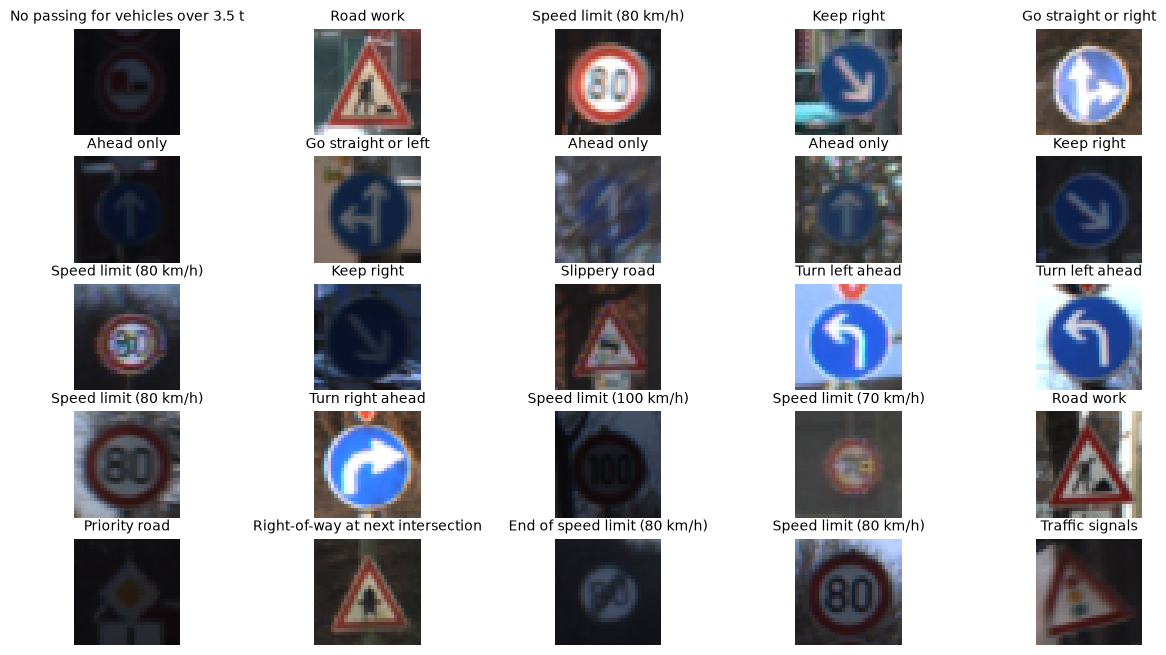

In [15]:
import importlib
import utils
importlib.reload(utils)
from utils import plot_random_images

plot_random_images(gtsrb_test, label_map, rows=5, columns=5)

#### Check Class Distribution

In [16]:
test_targets = [y for x, y in gtsrb_test._samples]
train_targets = [y for x, y in gtsrb_train._samples]

unique_train, counts_train = np.unique(train_targets, return_counts=True)
unique_test, counts_test = np.unique(test_targets, return_counts=True)

assert len(unique_train) == len(unique_test), ValueError("Missing targets.")

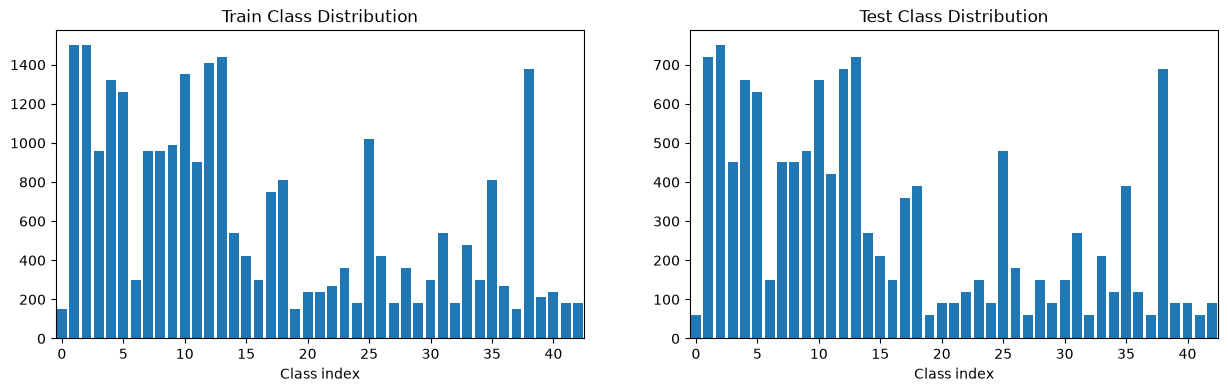

In [17]:
plt.figure(figsize=(15, 4))
plt.subplot(1, 2, 1)
plt.title("Train Class Distribution")
plt.bar(unique_train, counts_train)
plt.xlim([min(unique_train) - 0.5, max(unique_train) + 0.5])
plt.xlabel("Class index")
plt.subplot(1, 2, 2)
plt.title("Test Class Distribution")
plt.bar(unique_test, counts_test)
plt.xlim([min(unique_test) - 0.5, max(unique_test) + 0.5])
_ = plt.xlabel("Class index")

#### Define your CNN model class

In [18]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self, in_ch, n_classes, *args, **kwargs):
        super(SimpleCNN, self).__init__(*args, **kwargs)

        self.conv_sequence = nn.Sequential(
            nn.Conv2d(in_ch, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size=2, stride=2),
            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.ReLU(),
        )

        self.global_pool = nn.AdaptiveMaxPool2d(1)

        self.dense_sequence = nn.Sequential(
            nn.Linear(64, 64),
            nn.ReLU(),
            nn.Linear(64, n_classes)
        )
    
    def forward(self, x):
        z1 = self.conv_sequence(x)
        z2 = self.global_pool(z1).view(z1.shape[0], -1) # using .squeeze() instead of .view() won't work for GradCAM!
        z3 = self.dense_sequence(z2)

        return z3

In [20]:
from torchsummary import summary

model = SimpleCNN(in_ch=3, n_classes=43)

summary(model, (3, 32, 32), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 16, 32, 32]             448
              ReLU-2           [-1, 16, 32, 32]               0
            Conv2d-3           [-1, 32, 32, 32]           4,640
              ReLU-4           [-1, 32, 32, 32]               0
         MaxPool2d-5           [-1, 32, 16, 16]               0
            Conv2d-6           [-1, 64, 16, 16]          18,496
              ReLU-7           [-1, 64, 16, 16]               0
         MaxPool2d-8             [-1, 64, 8, 8]               0
            Conv2d-9             [-1, 64, 8, 8]          36,928
             ReLU-10             [-1, 64, 8, 8]               0
AdaptiveMaxPool2d-11             [-1, 64, 1, 1]               0
           Linear-12                   [-1, 64]           4,160
             ReLU-13                   [-1, 64]               0
           Linear-14                   

**Number of total parameters doesn't change with the input height/width! Why?**

### Training

In [21]:
# Define hyperparameters
batch_size = 128
epochs = 1
lr = 1e-3
print_frequency = 1

optimizer = torch.optim.Adam(model.parameters(), lr=lr)
loss = nn.CrossEntropyLoss()

In [22]:
from torch.utils.data import DataLoader

gtsrb_train_loader = DataLoader(gtsrb_train, batch_size=batch_size, shuffle=True)
gtsrb_test_loader = DataLoader(gtsrb_test, batch_size=batch_size, shuffle=False)

In [23]:
print(f"N.o. train batches: {len(gtsrb_train_loader)}. N.o. test batches: {len(gtsrb_test_loader)}")

N.o. train batches: 209. N.o. test batches: 99


In [24]:
if torch.cuda.is_available():
    device = torch.device('cuda')
else:
    device = torch.device('cpu')
print(f"Using {device}.")

Using cpu.


**Note:** `train_loop` is now modified to search for any existing model at path `filder_path/file_name`, and if found, will try to load that model and start training from it.

In [25]:
import os
from tqdm import tqdm
import torch_utils
importlib.reload(torch_utils)

# Define root folder and file_name for saving
folder_path = "models/gtsrb"
file_name = "model.pth"

_ = torch_utils.train_loop(
    model, 
    train_loader=gtsrb_train_loader, 
    optimizer=optimizer, 
    loss=loss, 
    epochs=epochs, 
    test_loader=gtsrb_test_loader, 
    device=device, 
    folder_path=folder_path, 
    file_name=file_name,
)

100%|██████████| 99/99 [00:06<00:00, 15.00it/s]

Epoch 1/1: train_loss=0.061333483044931476 train_acc=0.9797297297297297 test_loss=1.1116782742919344 test_acc=0.8224069675376089


#### Inspecting Confusion Matrix

In [26]:
import torch_utils
importlib.reload(torch_utils)

# load best model
model.load_state_dict(
    torch.load(
        os.path.join(folder_path, file_name)
    )["state_dict"]
)
model.to(device)

# get test predictions
y_train, y_train_pred = torch_utils.get_prediction_targets(model, gtsrb_train_loader, device=device)
y_test, y_test_pred = torch_utils.get_prediction_targets(model, gtsrb_test_loader, device=device)

100%|██████████| 99/99 [00:06<00:00, 16.34it/s]


In [27]:
assert y_train.shape == y_train_pred.shape
assert y_test.shape == y_test_pred.shape

In [28]:
from sklearn.metrics import confusion_matrix

train_cm = confusion_matrix(y_train, y_train_pred, normalize="true")
test_cm = confusion_matrix(y_test, y_test_pred, normalize="true")

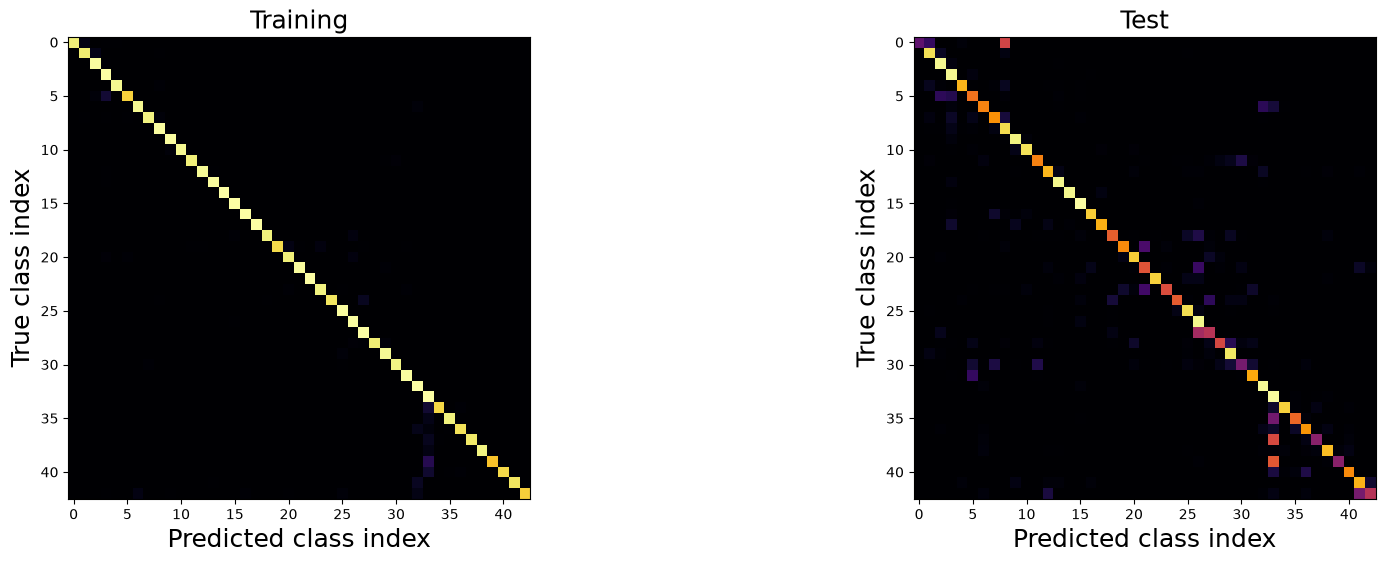

In [29]:
def plot_cm(cm_matrix, title=""):
    plt.imshow(cm_matrix, cmap="inferno")
    plt.xlabel("Predicted class index", fontdict={"fontsize": 18})
    plt.ylabel("True class index", fontdict={"fontsize": 18})
    plt.title(title, fontdict={"fontsize": 18})

plt.figure(figsize=(20, 6))
plt.subplot(1, 2, 1)
plot_cm(train_cm, "Training")
plt.subplot(1, 2, 2)
plot_cm(test_cm, "Test")

### **Visualizing Region Importance with Grad-CAM**

<div style="text-align: center;">
  <img src="imgs/gradcam.PNG" alt="description" width="800"/>
  <figcaption>Overview of Grad-CAM. Source: <a href=https://arxiv.org/pdf/1611.07450>Grad-CAM: Why did you say that?</a></figcaption>
</div>

In [30]:
try:
    import pytorch_grad_cam 
except:
    !pip install grad-cam

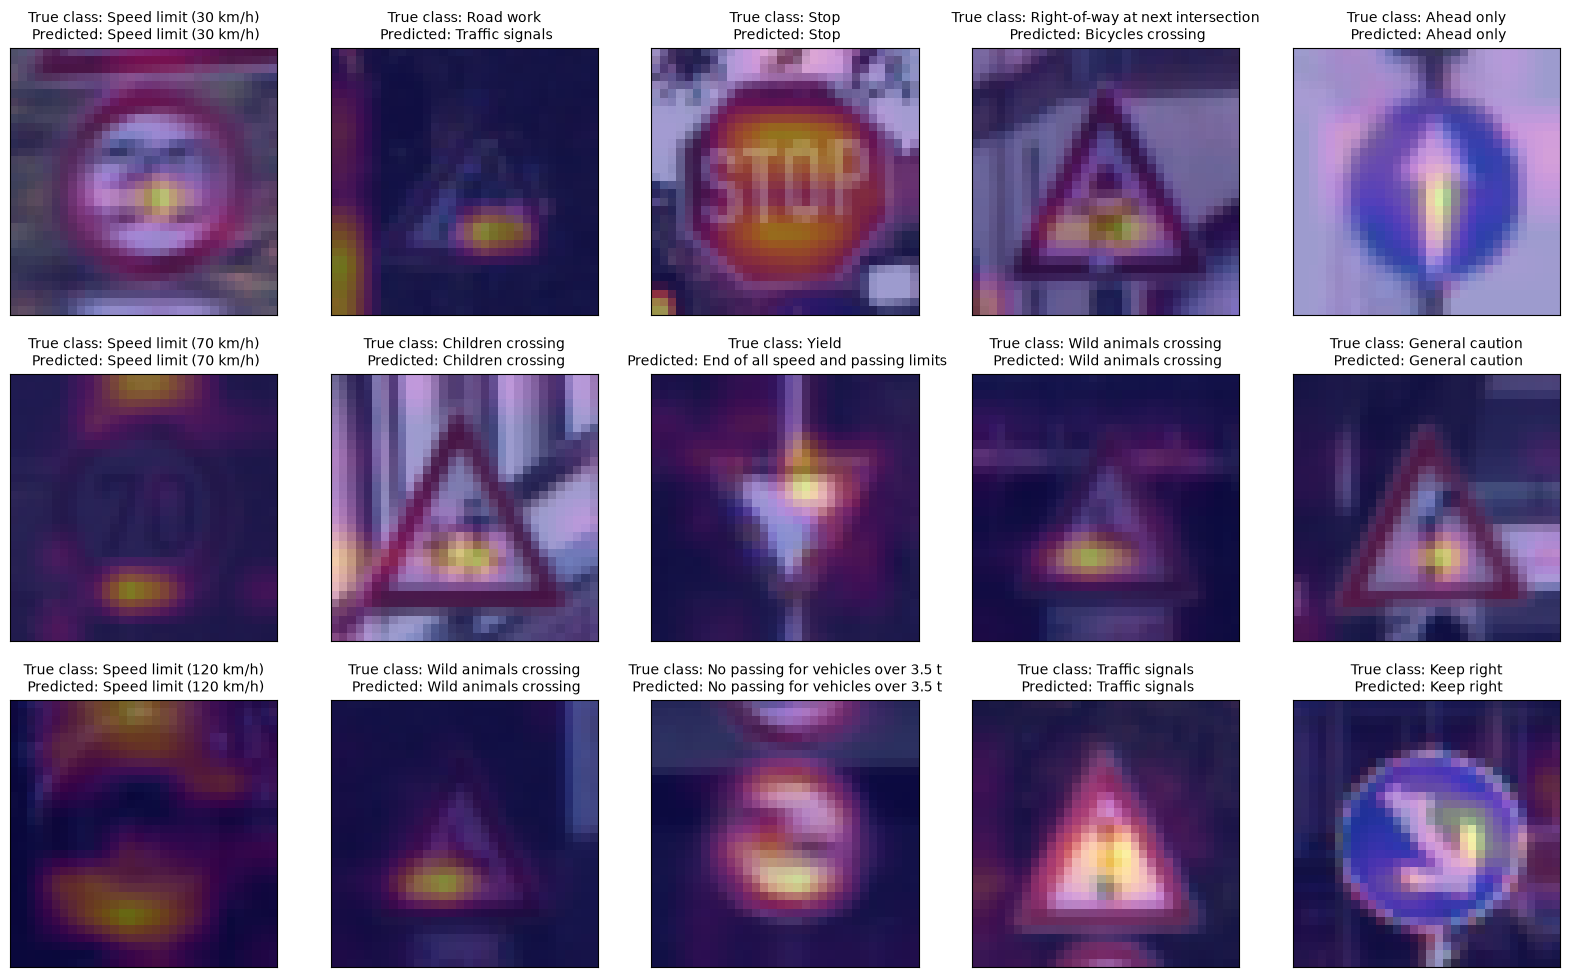

In [34]:
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget
importlib.reload(utils)

n_rows = 3
n_cols = 5
i = 1

plt.figure(figsize=(20, n_rows * 4))

target_layers = [model.conv_sequence[-1]]
gradcam = GradCAM(model, target_layers)

for images, targets in gtsrb_test_loader:
    idx = np.random.randint(0, images.shape[0])

    image = images[idx][None, ...].cpu()
    target = targets[idx][None, ...].cpu()
    target_prep = [ClassifierOutputTarget(target)]
    
    heatmap = gradcam(input_tensor=image, targets=target_prep, aug_smooth=False)

    predicted = torch.argmax(model(image.to(device)), dim=1)[0]

    plt.subplot(n_rows, n_cols, i)
    plt.title(f"True class: {label_map[target.data.numpy()[0]]}\n Predicted: {label_map[predicted.cpu().tolist()]}", fontdict={"fontsize": 10})
    utils.plot_image_with_heatmap_overlay(image[0], heatmap[0], alpha=0.4)

    i += 1
    if i > n_rows * n_cols:
        break
plt.show()

---

## **Transfer Learning (TL) / Fine-Tuning** <a class="anchor" id="tl"></a>

**Transfer learning** is technique where a model trained on one task is adapted for a second related task. It involves the following stages:
>1. Select a pre-trained model $T(\cdot)$ that was trained on a large source dataset $\mathbb{S}$, relevant to your problem
>2. Remove the Final Layer(s)
>3. Add Task-specific Layers - e.g. for classification, a final Linear layer with `#neurons = #classes` $\rightarrow$ new model $T'(\cdot)$
>4. Freeze the weights of pre-trained layers $\rightarrow T'$<sub>❄️</sub>
>5. Train $T'$<sub>❄️</sub> for some epochs (usually, only the newly added final layer is updated) on your choice dataset $\mathbb{D}$
>6. Fine-tune $T'$<sub>❄️</sub>:
>>   - Unfreeze all layers $\rightarrow$ $T'_🔥$
>>   - Train $T'_🔥$ for a number of epochs on $\mathbb{D}$

**TL** is particularly useful when at least one of the following holds: 
- dataset $\mathbb{D}$ is limited;
- we don't have enough computational resources to train $T(\cdot)$ from scratch;
- the domains of source and target tasks are roughly similar.

We'll use the pre-trained models from `torchvision.models`, but you can try other alternatives, such as [HuggingFace](https://huggingface.co/docs/transformers/model_doc/mobilenet_v1).

#### **Step 1: load pre-trained model**

In [35]:
from torchvision.models import squeezenet1_0

squeezenet = squeezenet1_0(pretrained=True)

/opt/anaconda3/envs/ia2_new/lib/python3.11/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/opt/anaconda3/envs/ia2_new/lib/python3.11/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=SqueezeNet1_0_Weights.IMAGENET1K_V1`. You can also use `weights=SqueezeNet1_0_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


#### **Step 2: check the architecture**

In [36]:
summary(squeezenet, (3, 32, 32), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 96, 13, 13]          14,208
              ReLU-2           [-1, 96, 13, 13]               0
         MaxPool2d-3             [-1, 96, 6, 6]               0
            Conv2d-4             [-1, 16, 6, 6]           1,552
              ReLU-5             [-1, 16, 6, 6]               0
            Conv2d-6             [-1, 64, 6, 6]           1,088
              ReLU-7             [-1, 64, 6, 6]               0
            Conv2d-8             [-1, 64, 6, 6]           9,280
              ReLU-9             [-1, 64, 6, 6]               0
             Fire-10            [-1, 128, 6, 6]               0
           Conv2d-11             [-1, 16, 6, 6]           2,064
             ReLU-12             [-1, 16, 6, 6]               0
           Conv2d-13             [-1, 64, 6, 6]           1,088
             ReLU-14             [-1, 6

The final `Sequential` can be accessed by `squeezenet.classifier`. We'll modify this to fit out task.

><ins>Obs.</ins>: Other pre-trained models have different output structure. E.g., the output of `resnet18` can be accessed through `resnet18.fc`.

#### **Step 3: freeze the model's parameters**

In [37]:
for param in squeezenet.parameters():
    param.requires_grad = False

#### **Step 4: replace the final layer with something fit for the current task**

In [38]:
squeezenet.classifier

Sequential(
  (0): Dropout(p=0.5, inplace=False)
  (1): Conv2d(512, 1000, kernel_size=(1, 1), stride=(1, 1))
  (2): ReLU(inplace=True)
  (3): AdaptiveAvgPool2d(output_size=(1, 1))
)

In [39]:
squeezenet.classifier = nn.Sequential(
    nn.Conv2d(512, 43, 1, 1),
    nn.Flatten()
)

Check which parameters are set to learnable (only the last classification layer should be set to `True`):

In [40]:
for name, param in squeezenet.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

classifier.0.weight torch.Size([43, 512, 1, 1])
classifier.0.bias torch.Size([43])


#### **Step 5: Define train config**

In [41]:
batch_size = 256
epochs_freezed = 1
epochs_unfreezed = 1
lr_freezed = 1e-3
lr_unfreezed = 1e-4
print_frequency = 1

optimizer = torch.optim.Adam(squeezenet.parameters(), lr=lr_freezed)
loss = nn.CrossEntropyLoss()

# Define root folder and file_name for saving
folder_path_tl = "models_tl/gtsrb_squeezenet"
file_name_freeze = "model_freeze.pth"
file_name_unfreeze = "model_unfreeze.pth"

#### **Step 6a: Train new classification head**

In [42]:
_ = torch_utils.train_loop(
    squeezenet, 
    train_loader=gtsrb_train_loader, 
    optimizer=optimizer, 
    loss=loss, 
    epochs=epochs_freezed, 
    test_loader=gtsrb_test_loader, 
    device=device, 
    folder_path=folder_path_tl, 
    file_name=file_name_freeze,
)

100%|██████████| 99/99 [00:12<00:00,  8.20it/s]

Epoch 1/1: train_loss=0.057903988518569455 train_acc=0.9822072072072072 test_loss=0.5560267260580352 test_acc=0.8863024544734759


#### **Step 6b: Unfreeze and Fine-tune**

In [43]:
squeezenet.load_state_dict(
    torch.load(
        os.path.join(folder_path_tl, file_name_freeze)
    )["state_dict"]
)
_ = squeezenet.to(device)

In [44]:
for param in squeezenet.parameters():
    param.requires_grad = True

optimizer = torch.optim.Adam(squeezenet.parameters(), lr=lr_unfreezed)

>A new optimizer is used to account for all parameters.

In [45]:
_ = torch_utils.train_loop(
    squeezenet, 
    train_loader=gtsrb_train_loader, 
    optimizer=optimizer, 
    loss=loss, 
    epochs=epochs_unfreezed, 
    test_loader=gtsrb_test_loader, 
    device=device, 
    folder_path=folder_path_tl, 
    file_name=file_name_unfreeze,
)

100%|██████████| 99/99 [00:13<00:00,  7.13it/s]

Epoch 1/1: train_loss=0.0349534002141626 train_acc=0.9880255255255255 test_loss=0.6066110204867642 test_acc=0.8920031670625495


#### Compare results

In [46]:
import torch_utils
importlib.reload(torch_utils)

# load best model
squeezenet.load_state_dict(
    torch.load(
        os.path.join(folder_path_tl, file_name_unfreeze)
    )["state_dict"]
)

# get test predictions
y_test, y_test_pred = torch_utils.get_prediction_targets(squeezenet, gtsrb_test_loader, device=device)

test_cm_squeeze = confusion_matrix(y_test, y_test_pred, normalize="true")

100%|██████████| 99/99 [00:10<00:00,  9.67it/s]


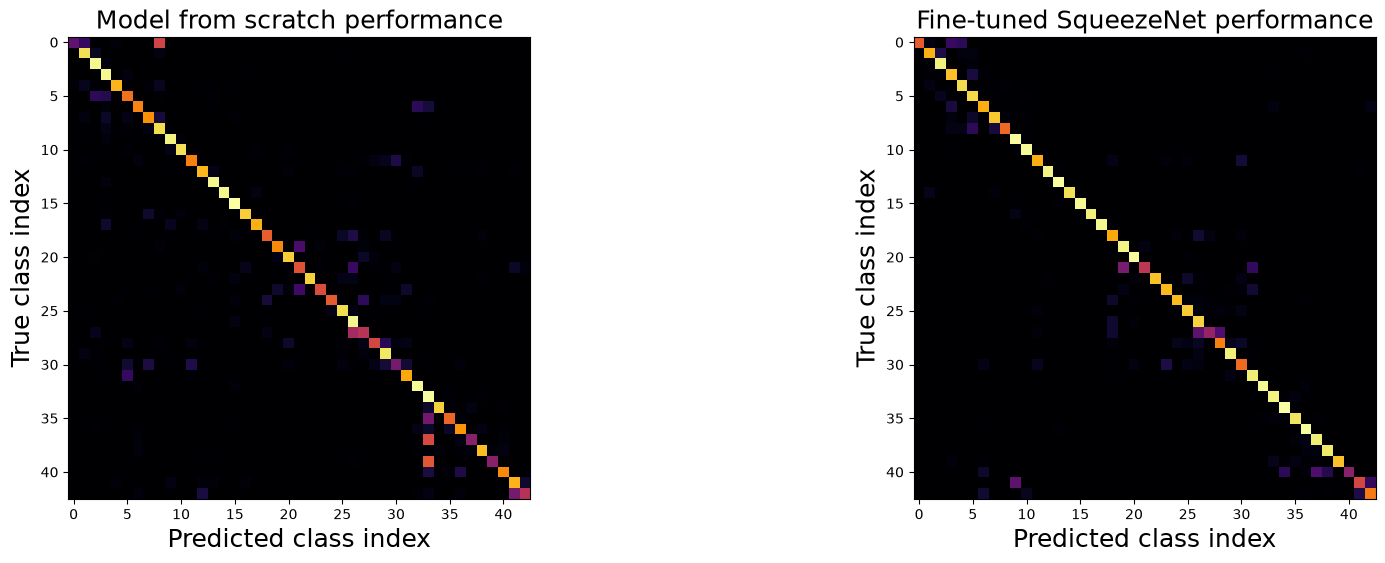

In [47]:
plt.figure(figsize=(20, 6))
plt.subplot(1, 2, 1)
plot_cm(test_cm, "Model from scratch performance")
plt.subplot(1, 2, 2)
plot_cm(test_cm_squeeze, "Fine-tuned SqueezeNet performance")

#### Summarize metrics from CMs

In [48]:
def compute_metrics_from_cm(conf_matrix):
    per_class_acc = np.diag(conf_matrix)
    per_class_prec = np.diag(conf_matrix) / (conf_matrix.sum(axis=0) + 1e-7)

    return per_class_acc, per_class_prec

In [49]:
acc_simple, prec_simple = compute_metrics_from_cm(test_cm)
acc_squeeze, prec_squeeze = compute_metrics_from_cm(test_cm_squeeze)

In [50]:
!pip install tabulate
import pandas as pd

df = pd.DataFrame({
    "Class": label_map.values(),
    "Simple CNN Accuracy": acc_simple,
    "Simple CNN Precision": prec_simple,
    "SqueezeNet Accuracy": acc_squeeze,
    "SqueezeNet Precision": prec_squeeze
})

df_overall  = pd.DataFrame({"Class": ["Overall Performance"],
                            "Simple CNN Accuracy": [np.mean(acc_simple)],
                            "Simple CNN Precision": [np.mean(prec_simple)],
                            "SqueezeNet Accuracy": [np.mean(acc_squeeze)],
                            "SqueezeNet Precision": [np.mean(prec_squeeze)]
                           })

line = [':------------------------']
df = pd.concat([df, 
                pd.DataFrame({
                    'Class': line,
                    "Simple CNN Accuracy": line,
                    "Simple CNN Precision": line,
                    "SqueezeNet Accuracy": line,
                    "SqueezeNet Precision": line
                }),
                df_overall], 
               ignore_index=True)

df_markdown = df.to_markdown(index=False)

In [51]:
print(df_markdown)

| Class                                    | Simple CNN Accuracy       | Simple CNN Precision      | SqueezeNet Accuracy       | SqueezeNet Precision      |
|:-----------------------------------------|:--------------------------|:--------------------------|:--------------------------|:--------------------------|
| Speed limit (20 km/h)                    | 0.26666666666666666       | 0.9621864409787421        | 0.6333333333333333        | 0.995237938843562         |
| Speed limit (30 km/h)                    | 0.9069444444444444        | 0.7464713428017549        | 0.8208333333333333        | 0.8598691996639121        |
| Speed limit (50 km/h)                    | 0.9626666666666667        | 0.7433688884809593        | 0.96                      | 0.8284241148680596        |
| Speed limit (60 km/h)                    | 0.9644444444444444        | 0.6758794158843561        | 0.8577777777777778        | 0.6840887582248825        |
| Speed limit (70 km/h)                    | 0.82272727272

❕**TIP**: By using [.to_csv()](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.DataFrame.to_csv.html) method you can save the table and convert it to LaTeX format using [this online tool](https://www.tablesgenerator.com/latex_tables), in order to organize your results more quickly.

---

## **Malware Image Classification** <a class="anchor" id="malware"></a>

In this section we apply the same recipe (inspect the data, define a CNN, train, evaluate) to a **security** problem: classifying malware into **families**.

[Nataraj et al. (2011)](https://dl.acm.org/doi/10.1145/2016904.2016908), *Malware Images: Visualization and Automatic Classification*, observed that if a binary file is read as a vector of 8-bit unsigned integers (values in $[0, 255]$) and reshaped into a 2D array, the result is a **grayscale image**. Different parts of an executable (code, data, resources, ...) have a different *texture*, and variants of the same malware family tend to look alike. This turns malware family identification into an image classification problem.

The image **width** is chosen from the file size (e.g. 32 pixels for files under 10 kB, up to 1024 pixels for files over 1 MB), and the **height** follows from the file length. Consequently, the images in the dataset **do not have the same size**.

<div style="text-align: center;">
  <img src="imgs/binary-image.PNG" alt="description" width="600"/>
  <figcaption>Example of a binary image <a href=https://github.com/safreita1/malnet-image>Example from MalNet</a></figcaption>
</div>

### Binaries as images

We won't touch real malware here. As a harmless example, we turn the Python executable of this environment into an image (only its first 400 kB, to keep the picture readable):

/opt/anaconda3/envs/ia2_new/bin/python: 409600 bytes -> image of shape (800, 512)


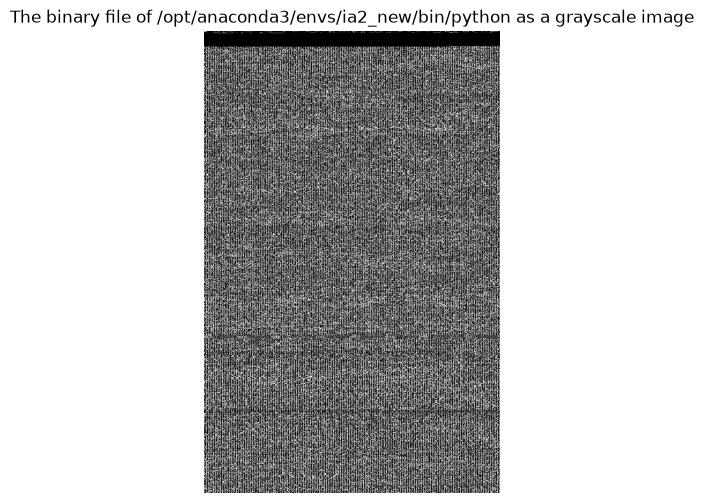

In [52]:
import sys
import numpy as np
import matplotlib.pyplot as plt

# Read (at most) the first 400 kB of a harmless executable, as a vector of 8-bit unsigned integers
file_path = sys.executable
data = np.fromfile(file_path, dtype=np.uint8, count=400 * 1024)

# Choose the image width as a function of the amount of data
size_kb = data.size / 1024
width_rules = [(10, 32), (30, 64), (60, 128), (100, 256), (200, 384), (500, 512), (1000, 768)]
width = next((w for limit, w in width_rules if size_kb < limit), 1024)

height = data.size // width
img = data[: height * width].reshape(height, width)  # drop the incomplete last row

print(f"{file_path}: {data.size} bytes -> image of shape {img.shape}")
plt.figure(figsize=(6, 6))
plt.imshow(img, cmap="gray")
plt.title(f"The binary file of {file_path} as a grayscale image")
plt.axis("off")
plt.show()

### **Malimg dataset** 🦠

The **Malimg** dataset contains malware samples already converted to grayscale images, grouped in **25 malware families**. Note that it contains **only malware** (no benign files), so the task is malware *family classification*, not malware *detection*.

The dataset can be downloaded from [Kaggle](https://www.kaggle.com/datasets/manmandes/malimg) without logging in:

In [53]:
import os
import zipfile

malimg_dir = "./data/malimg"
zip_path = "./data/malimg.zip"

if not os.path.exists(malimg_dir):
    os.makedirs("./data", exist_ok=True)
    !curl -L -o {zip_path} https://www.kaggle.com/api/v1/datasets/download/manmandes/malimg
    with zipfile.ZipFile(zip_path) as zf:
        zf.extractall(malimg_dir)

Let's list all the images and their families. The family of an image is the name of the folder that contains it (if the download is already split into `train`/`validation` folders, they are simply merged, since we will make our own split):

In [54]:
from PIL import Image

img_exts = (".png", ".jpg", ".jpeg", ".bmp")

records = []
for dirpath, _, filenames in os.walk(malimg_dir):
    for f in filenames:
        if f.lower().endswith(img_exts):
            records.append((os.path.join(dirpath, f), os.path.basename(dirpath)))

# Sort by (family, file name), so that the order is the same on any machine
records = sorted(records, key=lambda r: (r[1], os.path.basename(r[0])))

malimg_paths = np.array([r[0] for r in records])
classes = sorted(set(r[1] for r in records))
class_to_idx = {c: i for i, c in enumerate(classes)}
malimg_targets = np.array([class_to_idx[r[1]] for r in records])

print(f"{len(malimg_paths)} images from {len(classes)} families")
assert len(classes) == 25, f"Expected 25 families, found {len(classes)}. Check the folder structure of the download."
print(classes)

9339 images from 25 families
['Adialer.C', 'Agent.FYI', 'Allaple.A', 'Allaple.L', 'Alueron.gen!J', 'Autorun.K', 'C2LOP.P', 'C2LOP.gen!g', 'Dialplatform.B', 'Dontovo.A', 'Fakerean', 'Instantaccess', 'Lolyda.AA1', 'Lolyda.AA2', 'Lolyda.AA3', 'Lolyda.AT', 'Malex.gen!J', 'Obfuscator.AD', 'Rbot!gen', 'Skintrim.N', 'Swizzor.gen!E', 'Swizzor.gen!I', 'VB.AT', 'Wintrim.BX', 'Yuner.A']


Some images from different families, **at their original size**:

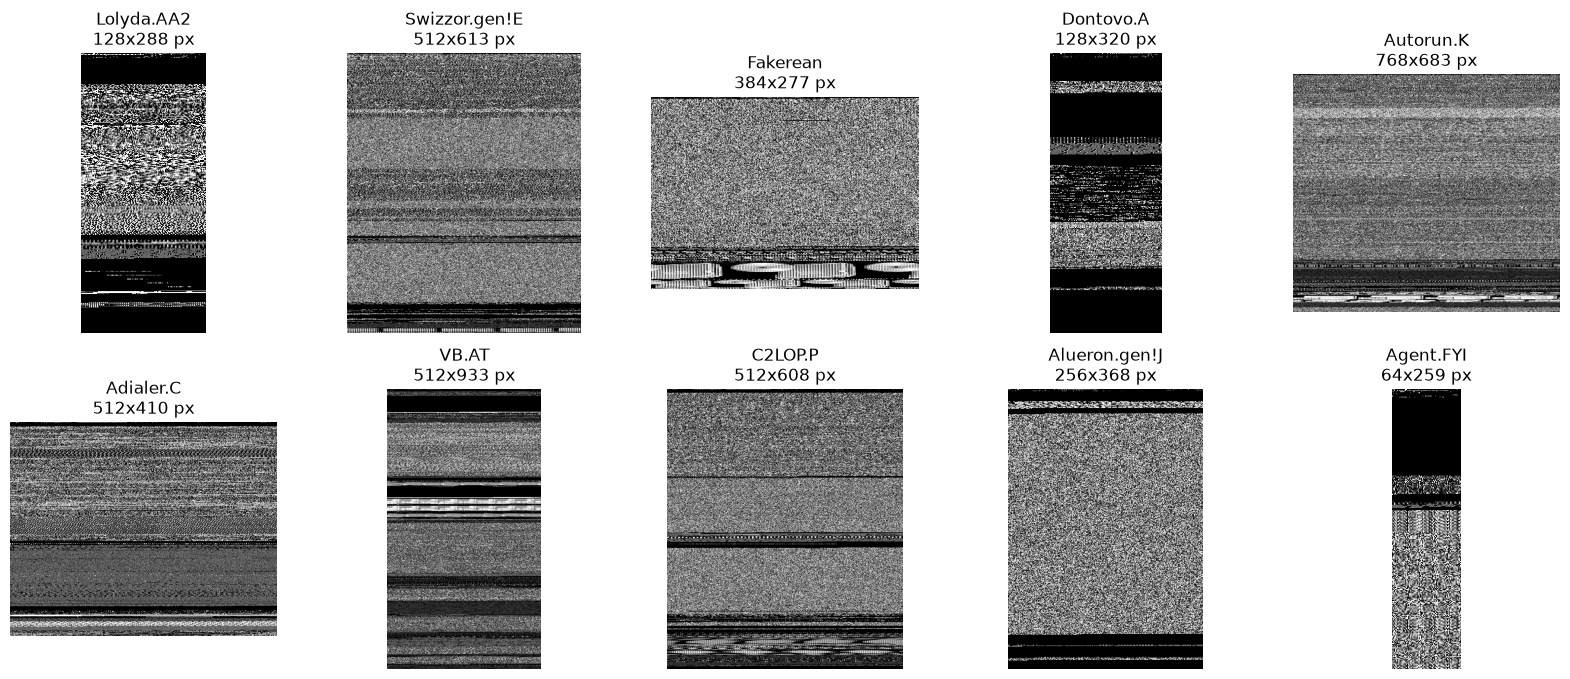

In [55]:
rng = np.random.default_rng(0)
shown_classes = rng.choice(len(classes), size=10, replace=False)

plt.figure(figsize=(20, 8))
for k, c in enumerate(shown_classes):
    i = rng.choice(np.where(malimg_targets == c)[0])
    im = Image.open(malimg_paths[i]).convert("L")
    plt.subplot(2, 5, k + 1)
    plt.imshow(im, cmap="gray")
    plt.title(f"{classes[c]}\n{im.width}x{im.height} px")
    plt.axis("off")
plt.show()

In [56]:
# Reading only the image headers is enough to get the sizes
sizes = np.array([Image.open(p).size for p in malimg_paths])  # (width, height)

print(f"Width:  min={sizes[:, 0].min()}, median={int(np.median(sizes[:, 0]))}, max={sizes[:, 0].max()}")
print(f"Height: min={sizes[:, 1].min()}, median={int(np.median(sizes[:, 1]))}, max={sizes[:, 1].max()}")

Width:  min=64, median=256, max=1024
Height: min=208, median=424, max=5334


❗Images have very different sizes, so we have to **resize** them to a common resolution before feeding them to the network. **Keep in mind that resizing could significantly distort the texture and hide important patterns.**

#### Train / validation / test split

Malimg has no official split, so we create our own: a **stratified** 70% / 15% / 15% split, which keeps the proportion of each family the same in all three partitions. The seed is fixed, so everyone gets **exactly the same split** (**do not change it in the homeworks**, so that results are comparable).

> **Caution**: images from the same family are often *very* similar to each other (some families even contain near-identical samples). With a random split, near-copies of training images end up in the test set, which makes the scores below *optimistic*. We will come back to this.

In [57]:
from sklearn.model_selection import train_test_split
import torchvision.transforms as transforms
from torch.utils.data import Dataset, DataLoader

seed = 42
all_idx = np.arange(len(malimg_paths))
train_idx, rest_idx = train_test_split(all_idx, test_size=0.30, stratify=malimg_targets, random_state=seed)
val_idx, test_idx = train_test_split(rest_idx, test_size=0.50, stratify=malimg_targets[rest_idx], random_state=seed)

print(f"Train: {len(train_idx)}, Validation: {len(val_idx)}, Test: {len(test_idx)}")

Train: 6537, Validation: 1401, Test: 1401


In [58]:
img_size = 128

malimg_transform = transforms.Compose([
    transforms.Resize((img_size, img_size)),
    transforms.ToTensor(),  # also scales the values to [0, 1]
])


class MalimgDataset(Dataset):
    def __init__(self, paths, targets, transform=None):
        self.paths = paths
        self.targets = targets
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("L")  # single channel
        if self.transform:
            img = self.transform(img)
        return img, int(self.targets[i])


malimg_train = MalimgDataset(malimg_paths[train_idx], malimg_targets[train_idx], malimg_transform)
malimg_val = MalimgDataset(malimg_paths[val_idx], malimg_targets[val_idx], malimg_transform)
malimg_test = MalimgDataset(malimg_paths[test_idx], malimg_targets[test_idx], malimg_transform)

x, y = malimg_train[0]
print("Input image size: ", x.shape)
print("Input image range: ", x.min().item(), x.max().item())
print("Label: ", y, classes[y])

Input image size:  torch.Size([1, 128, 128])
Input image range:  0.0 0.8313725590705872
Label:  2 Allaple.A


#### Check Class Distribution

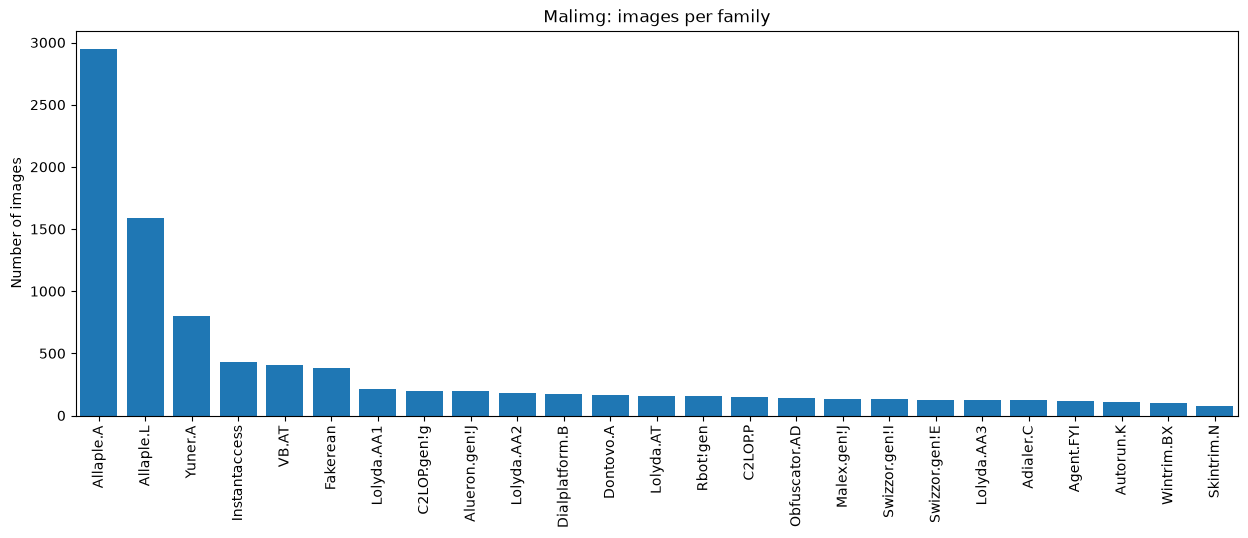

In [59]:
counts = np.bincount(malimg_targets, minlength=len(classes))
order = np.argsort(counts)[::-1]

plt.figure(figsize=(15, 5))
plt.bar(range(len(classes)), counts[order])
plt.xticks(range(len(classes)), [classes[i] for i in order], rotation=90)
plt.xlim([-0.5, len(classes) - 0.5])
plt.ylabel("Number of images")
_ = plt.title("Malimg: images per family")

In [60]:
import pandas as pd

split_counts = pd.DataFrame({
    "Train": np.bincount(malimg_targets[train_idx], minlength=len(classes)),
    "Validation": np.bincount(malimg_targets[val_idx], minlength=len(classes)),
    "Test": np.bincount(malimg_targets[test_idx], minlength=len(classes)),
}, index=classes)

split_counts.iloc[order]

,Train,Validation,Test
Allaple.A,2064,442,443
Allaple.L,1114,238,239
Yuner.A,560,120,120
Instantaccess,302,64,65
VB.AT,286,61,61
Fakerean,267,57,57
Lolyda.AA1,149,32,32
C2LOP.gen!g,140,30,30
Alueron.gen!J,139,30,29
Lolyda.AA2,129,27,28


**How many times larger is the largest family than the smallest? What accuracy would a model that always predicts the largest family get?**

In [61]:
mal_batch_size = 64

malimg_train_loader = DataLoader(malimg_train, batch_size=mal_batch_size, shuffle=True)
malimg_val_loader = DataLoader(malimg_val, batch_size=mal_batch_size, shuffle=False)
malimg_test_loader = DataLoader(malimg_test, batch_size=mal_batch_size, shuffle=False)

print(f"N.o. train batches: {len(malimg_train_loader)}. N.o. val batches: {len(malimg_val_loader)}. N.o. test batches: {len(malimg_test_loader)}")

N.o. train batches: 103. N.o. val batches: 22. N.o. test batches: 22


#### Simple CNN

We reuse the `SimpleCNN` defined above, changing only the number of input channels (1, since the images are grayscale) and the number of classes (25). Because of the global pooling, the architecture does not depend on the image resolution.

In [62]:
mal_model = SimpleCNN(in_ch=1, n_classes=len(classes))

summary(mal_model, (1, img_size, img_size), device="cpu")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 16, 128, 128]             160
              ReLU-2         [-1, 16, 128, 128]               0
            Conv2d-3         [-1, 32, 128, 128]           4,640
              ReLU-4         [-1, 32, 128, 128]               0
         MaxPool2d-5           [-1, 32, 64, 64]               0
            Conv2d-6           [-1, 64, 64, 64]          18,496
              ReLU-7           [-1, 64, 64, 64]               0
         MaxPool2d-8           [-1, 64, 32, 32]               0
            Conv2d-9           [-1, 64, 32, 32]          36,928
             ReLU-10           [-1, 64, 32, 32]               0
AdaptiveMaxPool2d-11             [-1, 64, 1, 1]               0
           Linear-12                   [-1, 64]           4,160
             ReLU-13                   [-1, 64]               0
           Linear-14                   

#### Training

We use the same `torch_utils.train_loop` as before, passing the **validation** loader (it is only monitored during training).

> **Note**: `train_loop` saves the checkpoint with the lowest *training* loss, and **resumes from an existing checkpoint** if `folder_path/file_name` already exists. When trying a different model or setting, use a **new `file_name`**, otherwise you may silently continue from an older model.

In [63]:
import torch_utils

mal_epochs = 1
mal_lr = 1e-3

mal_optimizer = torch.optim.Adam(mal_model.parameters(), lr=mal_lr)
mal_loss = nn.CrossEntropyLoss()

mal_folder_path = "models/malimg"
mal_file_name = "model.pth"

_ = torch_utils.train_loop(
    mal_model,
    train_loader=malimg_train_loader,
    optimizer=mal_optimizer,
    loss=mal_loss,
    epochs=mal_epochs,
    test_loader=malimg_val_loader,
    device=device,
    folder_path=mal_folder_path,
    file_name=mal_file_name,
)

100%|██████████| 22/22 [00:08<00:00,  2.74it/s]

Epoch 1/1: train_loss=0.2218575103624353 train_acc=0.9323848860333487 test_loss=0.18892489780079236 test_acc=0.9450392576730906


#### Evaluation

Since the families are highly imbalanced, **accuracy alone is misleading**: it is dominated by the largest families. We also report the **macro-F1** score, i.e. the average of the per-class F1 scores, where every family counts equally.

In [64]:
from sklearn.metrics import confusion_matrix, classification_report, f1_score, accuracy_score

# load best model
mal_model.load_state_dict(
    torch.load(
        os.path.join(mal_folder_path, mal_file_name)
    )["state_dict"]
)
mal_model.to(device)

y_val, y_val_pred = torch_utils.get_prediction_targets(mal_model, malimg_val_loader, device=device)
y_test, y_test_pred = torch_utils.get_prediction_targets(mal_model, malimg_test_loader, device=device)

for name, (y_true, y_pred) in {"Validation": (y_val, y_val_pred), "Test": (y_test, y_test_pred)}.items():
    print(f"{name}: accuracy = {accuracy_score(y_true, y_pred):.4f} | macro-F1 = {f1_score(y_true, y_pred, average='macro'):.4f}")

100%|██████████| 22/22 [00:09<00:00,  2.25it/s]

Validation: accuracy = 0.9450 | macro-F1 = 0.8665
Test: accuracy = 0.9493 | macro-F1 = 0.8736


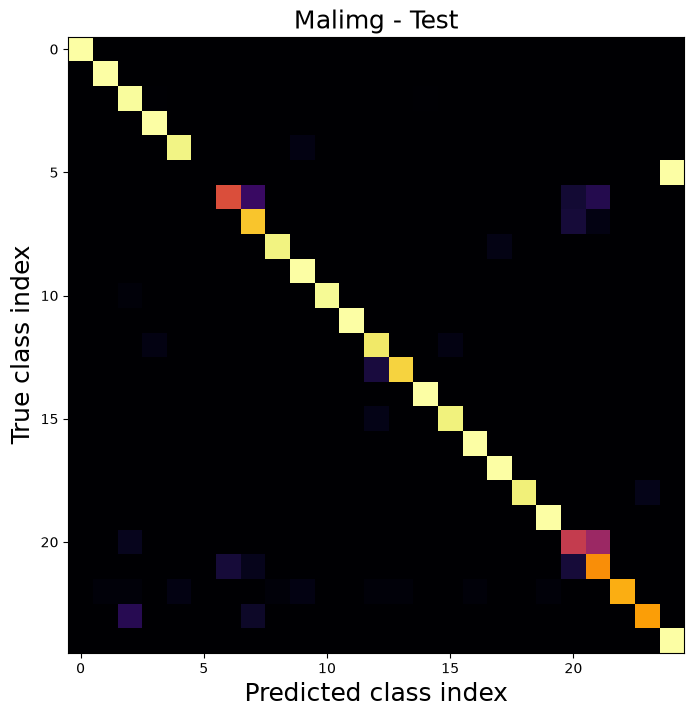

In [65]:
mal_test_cm = confusion_matrix(y_test, y_test_pred, normalize="true")

plt.figure(figsize=(10, 8))
plot_cm(mal_test_cm, "Malimg - Test")

In [66]:
report = classification_report(y_test, y_test_pred, target_names=classes, output_dict=True, zero_division=0)
mal_report_df = pd.DataFrame(report).T.loc[classes].round(3)
mal_report_df["support"] = mal_report_df["support"].astype(int)

mal_report_df.sort_values("support", ascending=False)

,precision,recall,f1-score,support
Allaple.A,0.989,0.991,0.990,443
Allaple.L,0.988,1.000,0.994,239
Yuner.A,0.882,1.000,0.938,120
Instantaccess,1.000,1.000,1.000,65
VB.AT,1.000,0.820,0.901,61
Fakerean,1.000,0.982,0.991,57
Lolyda.AA1,0.857,0.938,0.896,32
C2LOP.gen!g,0.812,0.867,0.839,30
Alueron.gen!J,0.933,0.966,0.949,29
Lolyda.AA2,0.962,0.893,0.926,28


**Which families are the hardest for the model? Is there a relation with the number of samples (`support`)? Which families does the model mix up, according to the confusion matrix (the axes show the class indices, in the order of the table above)?**

---

## 📓 Homework <a class="anchor" id="hw"></a>

Both homeworks are **individual** (40 pts each) and use the Malimg dataset, with **the same train/validation/test split from the lab** (do not change it).

### **Homework A** (40 pts, 1 person): Transfer Learning for Malware Family Classification <a class="anchor" id="hw_a"></a>

In the lab you trained a simple CNN on malware images from scratch. In this homework you will find out whether **ImageNet-pretrained models** transfer to this very different kind of image, and what you gain or lose as the model size grows.

Steps:
1. **Setup and Baselines** `(10 pts)`
   - Tune on the validation set only; report the test set once.
   - Reproduce the lab's simple CNN as a **baseline**: macro-F1, per-class precision/recall/F1 and the confusion matrix, on validation **and** test.
2. **Transfer Comparison** `(15 pts)`
   - Choose **at least 3 pretrained `torchvision` models of clearly different sizes** (small, medium, large), and justify the choice with their parameter counts `(3 x 5 pts)`.
   - For each, compare random initialization vs. pretrained weights, using the training recipe from the lab.
   - Report parameters, training time, inference time, macro-F1 and per-class recall, and compare everything against the lab baseline. Include **one plot or table relating model size to performance**.
3. **Investigate performance one the best model** `(15 pts)`

   Choose the best model from previous step and **two** of the following ablation studies:
   - **A. Data efficiency:** train on 1%, 5%, 10% and 100% of each family's samples, and plot pretrained vs. scratch learning curves.
   - **B. Feature-space analysis:** t-SNE/UMAP of frozen pretrained features vs. fine-tuned features, quantified with k-NN accuracy over the embedding vectors.
   - **C. Fine-tuning strategy:** compare a frozen backbone, full fine-tuning and at least one partial strategy (e.g. unfreezing only the last blocks), and study the effect of the learning rate (e.g. a grid, or different rates for the head and the backbone).

   Illustrate and discuss the results.

### **Homework B** (40 pts, 1 person): Explaining a Malware Image Classifier <a class="anchor" id="hw_b"></a>

Highly accurate malware classifiers are hard to trust without knowing *what they look at*. In this homework you will build your own CNN **from scratch** (no pretrained weights) and use explainability techniques to analyze its decisions.

Steps:
1. **Model Design and Baseline** `(10 pts)`
   - Design and tune your own architecture. Your model must reach a **validation macro-F1 of at least 90%❗**. Tune on the validation set only; report the test set once.
   - Document your design choices and what each one changed. Your model must stay compatible with Grad-CAM (see the note in the lab on `.view()` vs. `.squeeze()`).
   - Report macro-F1, per-class metrics and the confusion matrix.
2. **Explainability Techniques** `(15 pts)`
   - Apply **at least 3 explainability techniques** `(3 x 5 pts)` (e.g. Grad-CAM, Grad-CAM++, EigenCAM, ScoreCAM, ...) to the families assigned to you: one large family, one rare family and one confusable pair.
   - For **each technique, explore its hyperparameters** (e.g. target layer, smoothing options, window size) until the heatmaps are decent, and justify your final choice.
   - Show heatmaps for correctly classified and misclassified samples, and describe what each technique highlights.
3. **Quantitative Evaluation** `(15 pts)`
   - Apply **at least one quantitative evaluation** (e.g. deletion/insertion curves, or masking the top-k% most salient regions vs. random regions) to **all** your techniques, using their tuned settings, and compare them with it.
   - Discuss per-family differences and your findings. Be careful about claims you cannot verify (e.g. which part of the binary a region corresponds to), and state the limitations.

### Submission Rules (both homeworks)

No project report is required. Your submission will consist of:
1. A `.zip` or a public GitHub repository containing the source code. You can include all your homework in a single Jupyter notebook, provided you list any necessary dependencies.
2. A `10-minute` presentation in `.pdf` format, which will be presented in the last week of this course. The presentation should be made similar to [this Overleaf template](https://www.overleaf.com/latex/templates/uchicago-beamer/gpcrpvqzvdfr), and should include:
   - A brief description of the task: objective, dataset, model, training setup
   - Your methodology (the models you compared, or the explainability techniques you used and how you tuned them)
   - Your results and findings
   - Limitations
3. ⚠️ **Presentation is mandatory:** a homework submitted without being presented will **not be scored**.